In [1]:
# Pick up edits to `.py` files without restarting kernel
%load_ext autoreload
%autoreload 2

In [2]:
# Import libraries
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# Import modules
import config
from pipeline import *
from utils import *

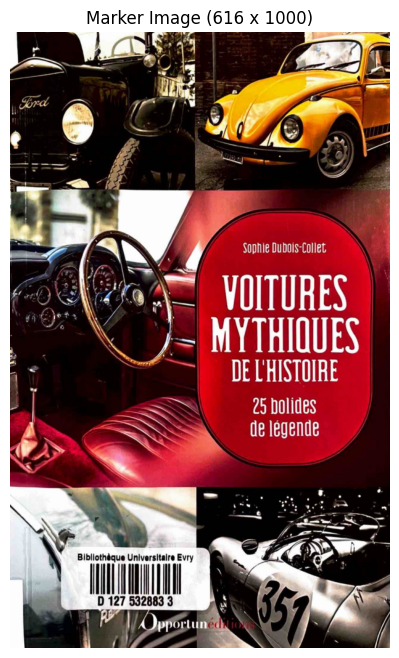

In [4]:
# Marker image
marker = load_image(config.MARKER_PATH)
marker = shrink_to_max_side(marker, config.MARKER_MAX_SIDE)
plot_image(marker, f"Marker Image ({marker.shape[1]} x {marker.shape[0]})")

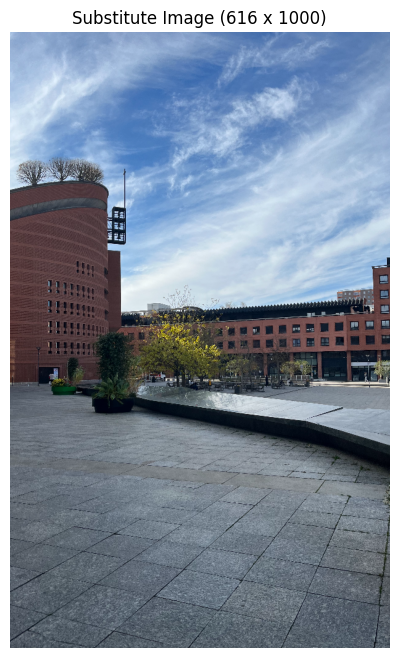

In [5]:
# Substitute image
substitute = load_image(config.SUBSTITUTE_PATH)
substitute = center_crop_to_size(substitute, marker.shape[1], marker.shape[0])
plot_image(substitute, f"Substitute Image ({substitute.shape[1]} x {substitute.shape[0]})")

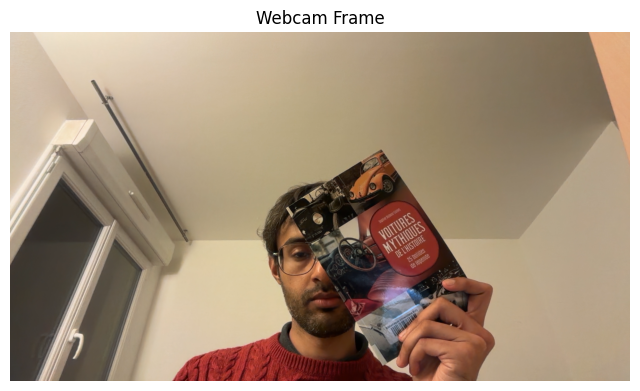

In [7]:
# Camera frame
if config.CAPTURE_NEW_FRAME:
    cv.imwrite(config.FRAME_PATH, grab_frame())
frame = load_image(config.FRAME_PATH)
plot_image(frame, "Webcam Frame")

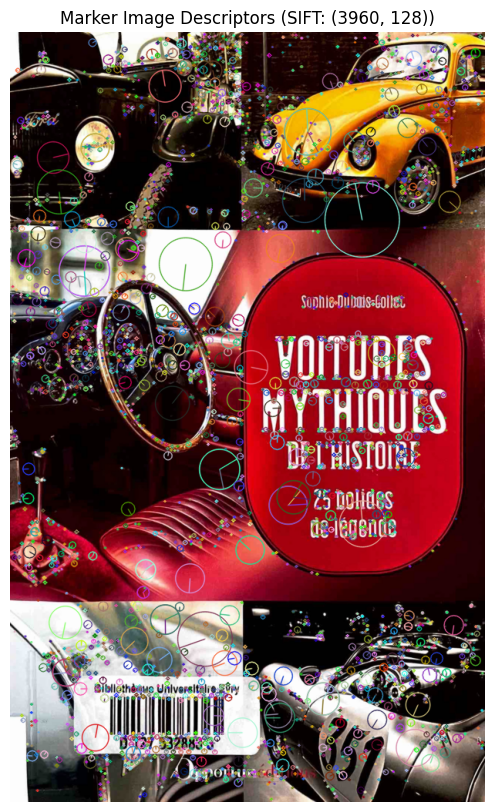

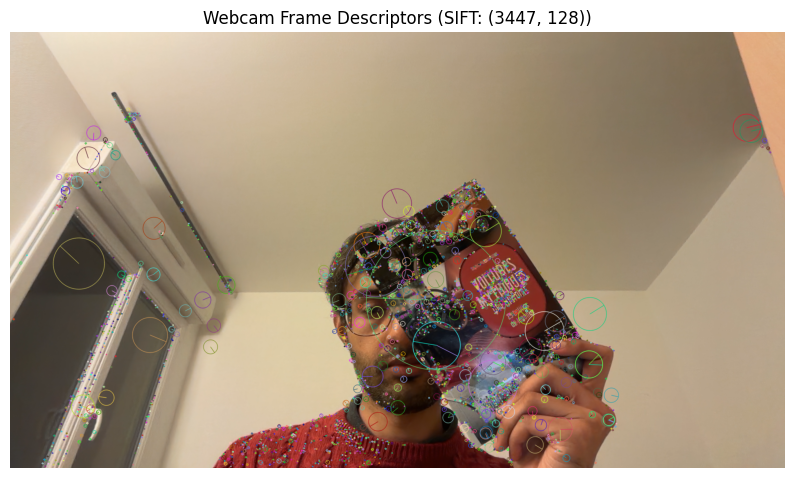

In [9]:
# Image descriptor extraction
detector = build_detector(config.DETECTOR_NAME)

# Marker keypoints
marker_keypoints, marker_descriptors = extract_features(detector, marker)
plot_image_with_keypoints(
    marker,
    marker_keypoints,
    f"Marker Image Descriptors ({config.DETECTOR_NAME}: {marker_descriptors.shape})",
    10
)

# Frame keypoints
frame_keypoints, frame_descriptors = extract_features(detector, frame)
plot_image_with_keypoints(
    frame,
    frame_keypoints,
    f"Webcam Frame Descriptors ({config.DETECTOR_NAME}: {frame_descriptors.shape})",
    10
)